# Session 7 · Advanced Unsupervised Learning: Clustering Algorithms

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-07-advanced-clustering-algorithms.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: agglomerative clustering and a dendrogram

first 4 merges (a, b, distance, size):
 [[ 0.   11.    0.24  2.  ]
 [ 4.    7.    0.45  2.  ]
 [ 9.   10.    0.51  2.  ]
 [ 2.    5.    0.53  2.  ]]
group 1: Islamabad, Murree
group 2: Quetta, Gilgit
group 3: Karachi, Gwadar
group 4: Hyderabad, Sukkur, Lahore, Faisalabad, Multan, Peshawar


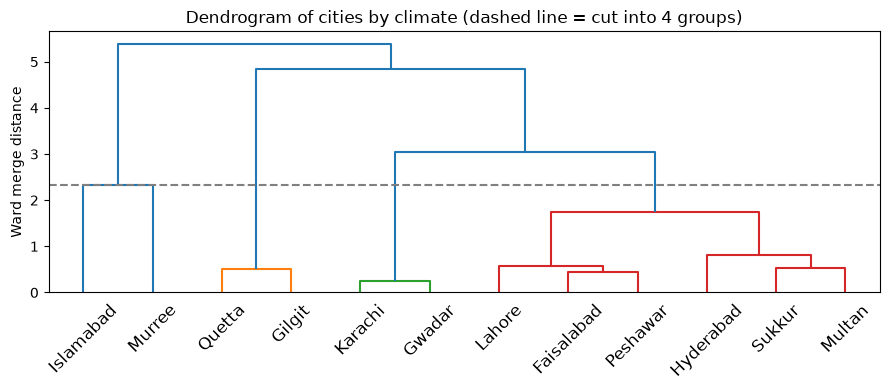

In [1]:
"""Hierarchical clustering of 12 cities by climate with SciPy: linkage matrix, dendrogram, cutting the tree."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler

cities = pd.DataFrame({
    "city": ["Karachi", "Hyderabad", "Sukkur", "Lahore", "Faisalabad", "Multan",
             "Islamabad", "Peshawar", "Murree", "Quetta", "Gilgit", "Gwadar"],
    "avg_temp_c": [26.5, 27.5, 27.0, 24.5, 24.5, 26.0, 21.5, 23.0, 13.5, 15.5, 16.0, 26.5],
    "rain_mm":    [175, 160, 95, 630, 380, 190, 1140, 460, 1700, 250, 140, 100],
    "humidity":   [70, 55, 45, 55, 55, 50, 58, 52, 70, 35, 40, 72],
})
X = StandardScaler().fit_transform(cities[["avg_temp_c", "rain_mm", "humidity"]])
Z = linkage(X, method="ward")                       # each row: cluster a, cluster b, distance, size
print("first 4 merges (a, b, distance, size):\n", np.round(Z[:4], 2))
cities["group"] = fcluster(Z, t=4, criterion="maxclust")
for g, names in cities.groupby("group")["city"]:
    print(f"group {g}: {', '.join(names)}")

plt.figure(figsize=(9, 4))
dendrogram(Z, labels=cities["city"].tolist(), leaf_rotation=45, color_threshold=Z[-4, 2])
plt.axhline(Z[-4, 2], ls="--", color="grey"); plt.ylabel("Ward merge distance")
plt.title("Dendrogram of cities by climate (dashed line = cut into 4 groups)")
plt.tight_layout(); plt.savefig("session-07_dendrogram.png", dpi=110); plt.show()

### Example 2 · Intermediate: comparing linkage methods

In [2]:
"""Ward, complete, average and single linkage on three data shapes, scored with ARI."""
import numpy as np
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

shapes = {
    "blobs": make_blobs(500, centers=3, cluster_std=1.0, random_state=1),
    "moons": make_moons(500, noise=.05, random_state=1),
    "circles": make_circles(500, noise=.04, factor=.5, random_state=1),
}
print(f"{'linkage':<10}" + "".join(f"{s:>10}" for s in shapes))
for link in ["ward", "complete", "average", "single"]:
    row = f"{link:<10}"
    for name, (X, y) in shapes.items():
        lab = AgglomerativeClustering(n_clusters=len(set(y)), linkage=link).fit_predict(StandardScaler().fit_transform(X))
        row += f"{adjusted_rand_score(y, lab):>10.2f}"
    print(row)

linkage        blobs     moons   circles
ward            0.95      0.14      0.00
complete        0.95      0.56      0.01
average         0.98      0.49      0.02
single          0.57      1.00      1.00


### Example 3 · Intermediate: DBSCAN, the k-distance plot and parameter effects

95th percentile of 5-NN distance (near the knee): 0.194

  eps  clusters  noise points  core points
 0.08        11            93          506
 0.15         3            35          644
 0.19         3            32          656
 0.40         2            23          666
 0.80         1             5          680


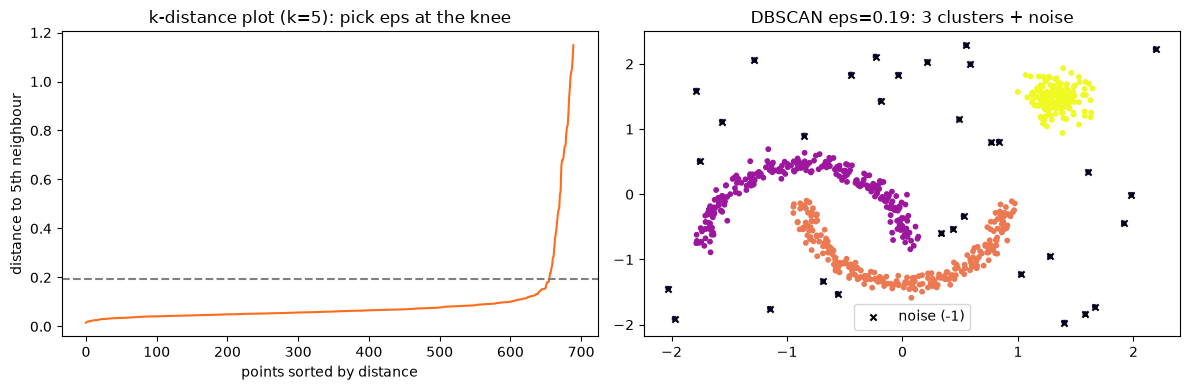

In [3]:
"""Choose eps for DBSCAN with a k-distance plot, then see how eps changes clusters and noise."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

rng = np.random.default_rng(0)
moons, _ = make_moons(500, noise=.06, random_state=0)
blob, _ = make_blobs(150, centers=[[2.5, 1.8]], cluster_std=.15, random_state=0)
noise = rng.uniform([-1.5, -1], [3.5, 2.5], (40, 2))
X = StandardScaler().fit_transform(np.vstack([moons, blob, noise]))

k = 5
dist, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)
kdist = np.sort(dist[:, -1])
knee = kdist[int(len(kdist) * .95)]
print(f"95th percentile of {k}-NN distance (near the knee): {knee:.3f}")

print("\n  eps  clusters  noise points  core points")
for eps in [0.08, 0.15, knee, 0.4, 0.8]:
    db = DBSCAN(eps=eps, min_samples=k).fit(X)
    n_cl = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    print(f"{eps:5.2f}  {n_cl:>8}  {(db.labels_ == -1).sum():>12}  {len(db.core_sample_indices_):>11}")

db = DBSCAN(eps=knee, min_samples=k).fit(X)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(kdist, color="#FF6B1A"); ax[0].axhline(knee, ls="--", color="grey")
ax[0].set_title(f"k-distance plot (k={k}): pick eps at the knee"); ax[0].set_xlabel("points sorted by distance"); ax[0].set_ylabel(f"distance to {k}th neighbour")
ax[1].scatter(X[:, 0], X[:, 1], c=db.labels_, cmap="plasma", s=10)
ax[1].scatter(X[db.labels_ == -1, 0], X[db.labels_ == -1, 1], c="black", marker="x", s=20, label="noise (-1)")
ax[1].set_title(f"DBSCAN eps={knee:.2f}: 3 clusters + noise"); ax[1].legend()
fig.tight_layout(); fig.savefig("session-07_dbscan.png", dpi=110); plt.show()

### Example 4 · Advanced: GMM vs K-means, soft membership and BIC

K-means ARI: 0.693

components  BIC (full covariance)
         1      9042.9
         2      8268.6
         3      6917.3
         4      6953.0


         5      6996.9
         6      7025.2
best by BIC: 3 components | GMM ARI: 0.942
covariance_type=spherical  ARI 0.574  BIC   8890.5
covariance_type=diag       ARI 0.662  BIC   8853.9
covariance_type=tied       ARI 0.678  BIC   8874.2
covariance_type=full       ARI 0.942  BIC   6917.3

points with less than 80% membership in any component: 35
example soft membership: [0.   0.54 0.46]


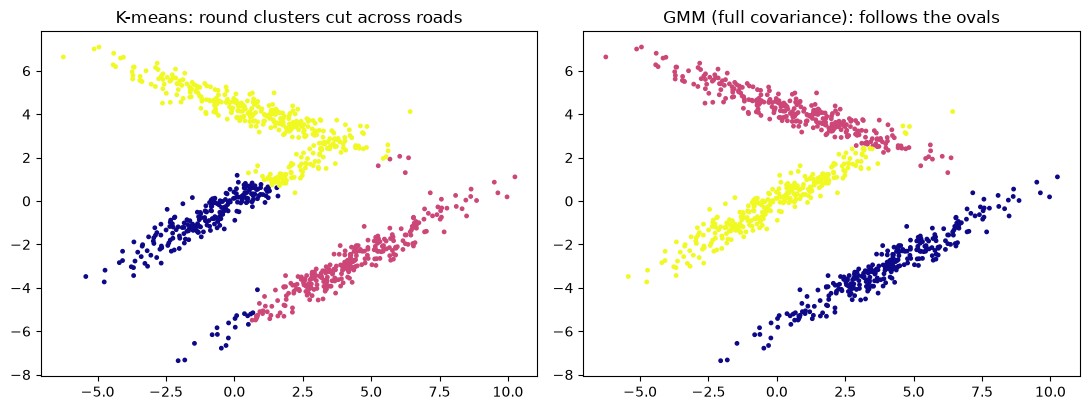

In [4]:
"""Elongated clusters: K-means vs Gaussian mixture, choosing components by BIC, soft probabilities."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

rng = np.random.default_rng(2)
# Three stretched, tilted groups (e.g. commuter trips along three roads)
def stretched(center, angle, n):
    pts = rng.normal(size=(n, 2)) * [2.5, .35]
    R = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    return pts @ R.T + center
X = np.vstack([stretched([0, 0], .6, 300), stretched([4, -3], .6, 300), stretched([1, 4], -.4, 300)])
y = np.repeat([0, 1, 2], 300)

km = KMeans(3, n_init=10, random_state=0).fit(X)
print(f"K-means ARI: {adjusted_rand_score(y, km.labels_):.3f}")
print("\ncomponents  BIC (full covariance)")
bics = {}
for k in range(1, 7):
    bics[k] = GaussianMixture(k, covariance_type="full", random_state=0).fit(X).bic(X)
    print(f"{k:>10}  {bics[k]:10.1f}")
best = min(bics, key=bics.get)
gmm = GaussianMixture(best, covariance_type="full", random_state=0).fit(X)
print(f"best by BIC: {best} components | GMM ARI: {adjusted_rand_score(y, gmm.predict(X)):.3f}")

for ctype in ["spherical", "diag", "tied", "full"]:
    g = GaussianMixture(3, covariance_type=ctype, random_state=0).fit(X)
    print(f"covariance_type={ctype:<9}  ARI {adjusted_rand_score(y, g.predict(X)):.3f}  BIC {g.bic(X):8.1f}")

probs = gmm.predict_proba(X)
unsure = (probs.max(axis=1) < .8).sum()
print(f"\npoints with less than 80% membership in any component: {unsure}")
print("example soft membership:", probs[np.argmin(probs.max(axis=1))].round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(X[:, 0], X[:, 1], c=km.labels_, cmap="plasma", s=6); ax[0].set_title("K-means: round clusters cut across roads")
ax[1].scatter(X[:, 0], X[:, 1], c=gmm.predict(X), cmap="plasma", s=6); ax[1].set_title("GMM (full covariance): follows the ovals")
fig.tight_layout(); fig.savefig("session-07_gmm_vs_kmeans.png", dpi=110); plt.show()

### Example 5 · Advanced: evaluation metrics and Mean Shift vs K-means vs DBSCAN

In [5]:
"""Internal and external clustering metrics for K-means, DBSCAN and Mean Shift on blobs and moons."""
import numpy as np
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, MeanShift, estimate_bandwidth
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)

data = {"blobs": make_blobs(600, centers=4, cluster_std=.9, random_state=3),
        "moons": make_moons(600, noise=.06, random_state=3)}
print(f"{'data':<6}{'algorithm':<11}{'k found':>8}{'silh':>7}{'DB':>7}{'CH':>8}{'ARI':>7}{'NMI':>7}")
for dname, (X, y) in data.items():
    X = StandardScaler().fit_transform(X)
    bw = estimate_bandwidth(X, quantile=.2, random_state=0)
    algos = {"K-means": KMeans(len(set(y)), n_init=10, random_state=0),
             "DBSCAN": DBSCAN(eps=.25, min_samples=5),
             "MeanShift": MeanShift(bandwidth=bw)}
    for aname, algo in algos.items():
        lab = algo.fit_predict(X)
        mask = lab != -1                                       # internal metrics ignore DBSCAN noise
        k = len(set(lab[mask]))
        sil = silhouette_score(X[mask], lab[mask]) if k > 1 else float("nan")
        dbi = davies_bouldin_score(X[mask], lab[mask]) if k > 1 else float("nan")
        ch = calinski_harabasz_score(X[mask], lab[mask]) if k > 1 else float("nan")
        print(f"{dname:<6}{aname:<11}{k:>8}{sil:>7.2f}{dbi:>7.2f}{ch:>8.0f}"
              f"{adjusted_rand_score(y, lab):>7.2f}{normalized_mutual_info_score(y, lab):>7.2f}")

data  algorithm   k found   silh     DB      CH    ARI    NMI
blobs K-means           4   0.76   0.34    7185   1.00   1.00
blobs DBSCAN            4   0.76   0.34    7261   0.99   0.99


blobs MeanShift         4   0.76   0.34    7185   1.00   1.00
moons K-means           2   0.49   0.81     833   0.48   0.39
moons DBSCAN            2   0.39   1.02     522   1.00   1.00


moons MeanShift         3   0.36   1.17     536   0.47   0.48


### 🏙️ Real-life data problem: finding ride-hailing pickup hotspots

pickups: 3000

DBSCAN (eps=300 m): 6 hotspots, 463 pickups treated as stray
         pickups  centre_lat  centre_lon        area
cluster                                             
2            595     24.9178     67.0968     Gulshan
0            473     24.8602     67.0104      Saddar
1            444     24.8137     67.0301     Clifton
4            397     24.8718     67.0597  Tariq Road
3            345     24.8991     67.1679     Airport
5            283     24.7952     67.0648    DHA Ph 6

stray pickups absorbed into a 'hotspot' -> K-means: 400 of 400 (every point is assigned)
stray pickups correctly left out by DBSCAN: 381 of 400
GMM: stray pickups with low likelihood (bottom 15%): 330 of 400


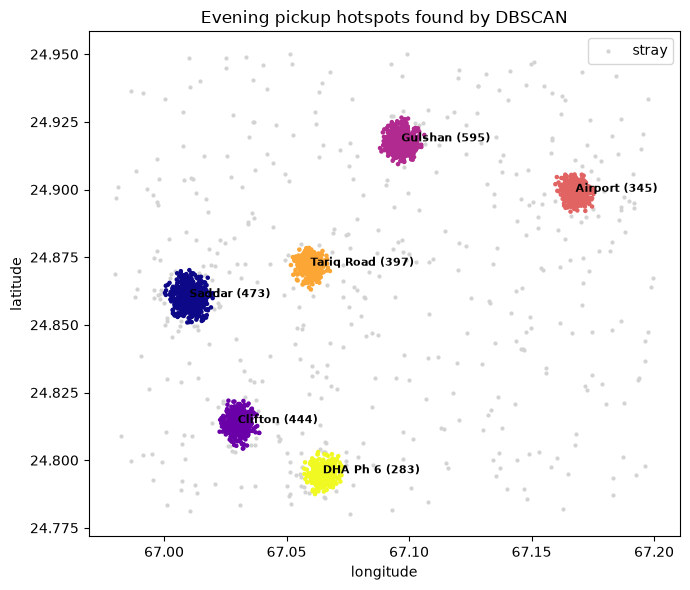

In [6]:
"""Real-life problem: GPS pickup hotspots with DBSCAN (haversine metres), compared with K-means and GMM."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, KMeans
from sklearn.mixture import GaussianMixture

rng = np.random.default_rng(10)
EARTH_R = 6_371_000                                   # metres
hotspots = {"Saddar": (24.8607, 67.0104, 500), "Clifton": (24.8138, 67.0300, 450), "Gulshan": (24.9180, 67.0971, 600),
            "Airport": (24.8990, 67.1680, 350), "Tariq Road": (24.8720, 67.0600, 400), "DHA Ph 6": (24.7950, 67.0650, 300)}
rows = []
for name, (lat, lon, n) in hotspots.items():
    spread = rng.uniform(.0025, .0045)                # roughly 250-500 m
    rows.append(np.c_[rng.normal(lat, spread, n), rng.normal(lon, spread, n)])
stray = np.c_[rng.uniform(24.78, 24.95, 400), rng.uniform(66.98, 67.20, 400)]
pts = np.vstack(rows + [stray])
print("pickups:", len(pts))

# DBSCAN with haversine: inputs in radians, eps = metres / Earth radius
eps_m = 300
db = DBSCAN(eps=eps_m / EARTH_R, min_samples=25, metric="haversine", algorithm="ball_tree").fit(np.radians(pts))
lab = db.labels_
summary = (pd.DataFrame({"lat": pts[:, 0], "lon": pts[:, 1], "cluster": lab})
           .query("cluster != -1").groupby("cluster")
           .agg(pickups=("lat", "size"), centre_lat=("lat", "mean"), centre_lon=("lon", "mean"))
           .sort_values("pickups", ascending=False))
def nearest(lat, lon):
    return min(hotspots, key=lambda h: (hotspots[h][0] - lat) ** 2 + (hotspots[h][1] - lon) ** 2)
summary["area"] = [nearest(a, b) for a, b in zip(summary.centre_lat, summary.centre_lon)]
print(f"\nDBSCAN (eps={eps_m} m): {len(summary)} hotspots, {(lab == -1).sum()} pickups treated as stray")
print(summary.round(4).to_string())

km = KMeans(6, n_init=10, random_state=0).fit(pts)
gmm = GaussianMixture(6, random_state=0).fit(pts)
stray_mask = np.arange(len(pts)) >= len(pts) - 400
print(f"\nstray pickups absorbed into a 'hotspot' -> K-means: {stray_mask.sum()} of 400 (every point is assigned)")
print(f"stray pickups correctly left out by DBSCAN: {(lab[stray_mask] == -1).sum()} of 400")
print(f"GMM: stray pickups with low likelihood (bottom 15%): "
      f"{(gmm.score_samples(pts)[stray_mask] < np.percentile(gmm.score_samples(pts), 15)).sum()} of 400")

plt.figure(figsize=(7, 6))
plt.scatter(pts[lab == -1, 1], pts[lab == -1, 0], s=4, color="lightgrey", label="stray")
plt.scatter(pts[lab != -1, 1], pts[lab != -1, 0], c=lab[lab != -1], cmap="plasma", s=5)
for _, r in summary.iterrows():
    plt.annotate(f"{r.area} ({r.pickups})", (r.centre_lon, r.centre_lat), fontsize=8, weight="bold")
plt.xlabel("longitude"); plt.ylabel("latitude"); plt.title("Evening pickup hotspots found by DBSCAN"); plt.legend()
plt.tight_layout(); plt.savefig("session-07_hotspots.png", dpi=110); plt.show()

### 🧩 Mini project: segmenting an image's colours with K-means and Mean Shift

K-means land cover: {'soil': '62.4%', 'vegetation': '17.5%', 'water': '12.8%', 'road': '7.3%'}
Mean Shift found 4 colour groups by itself (bandwidth 0.103)


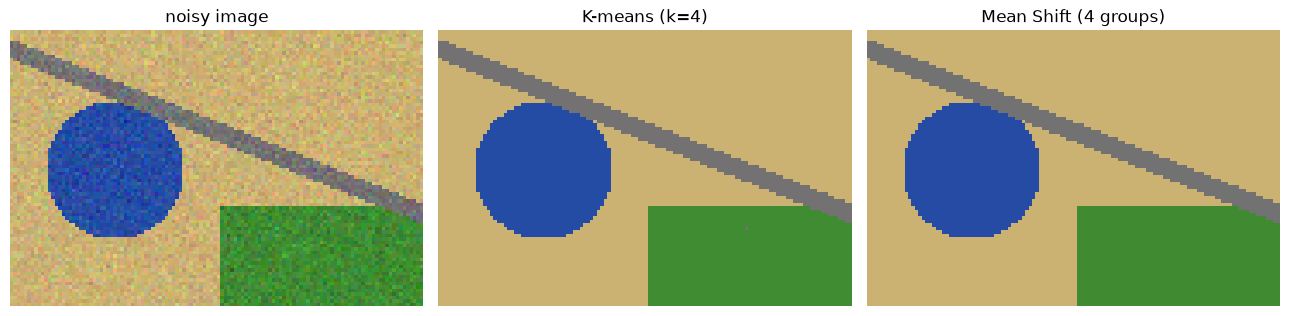

In [7]:
"""Mini project: colour segmentation of a synthetic satellite image with K-means and Mean Shift."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth

rng = np.random.default_rng(1)
H, W = 80, 120
yy, xx = np.mgrid[0:H, 0:W]
img = np.zeros((H, W, 3))
img[:] = [0.80, 0.70, 0.45]                                            # desert / bare soil
img[(xx - 30) ** 2 + (yy - 40) ** 2 < 400] = [0.15, 0.30, 0.65]       # lake
img[(yy > 50) & (xx > 60)] = [0.25, 0.55, 0.20]                       # farmland
img[(np.abs(yy - 0.4 * xx - 5) < 3)] = [0.45, 0.45, 0.45]             # road
img = np.clip(img + rng.normal(0, .05, img.shape), 0, 1)

pixels = img.reshape(-1, 3)
km = KMeans(4, n_init=10, random_state=0).fit(pixels)
seg_km = km.cluster_centers_[km.labels_].reshape(img.shape)
sample = pixels[rng.choice(len(pixels), 2000, replace=False)]
bw = estimate_bandwidth(sample, quantile=.1, random_state=0)
ms = MeanShift(bandwidth=bw, bin_seeding=True).fit(sample)
ms_labels = ms.predict(pixels)
seg_ms = ms.cluster_centers_[ms_labels].reshape(img.shape)

names = {0: "?", 1: "?", 2: "?", 3: "?"}
for j, c in enumerate(km.cluster_centers_):
    names[j] = "water" if c[2] > .5 else "vegetation" if c[1] > c[0] else "road" if abs(c[0] - c[1]) < .05 else "soil"
share = np.bincount(km.labels_) / len(pixels)
print("K-means land cover:", {names[j]: f"{share[j]:.1%}" for j in range(4)})
print(f"Mean Shift found {len(ms.cluster_centers_)} colour groups by itself (bandwidth {bw:.3f})")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, im, t in zip(ax, [img, seg_km, seg_ms], ["noisy image", "K-means (k=4)", f"Mean Shift ({len(ms.cluster_centers_)} groups)"]):
    a.imshow(im); a.set_title(t); a.axis("off")
fig.tight_layout(); fig.savefig("session-07_mini_project_segmentation.png", dpi=110); plt.show()